In [1]:

import sys
import sklearn
import pandas as pd
import matplotlib

print("Python :", sys.version)
print("Scikit-learn :", sklearn.__version__)
print("Pandas :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)


Python : 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Scikit-learn : 1.9.0
Pandas : 3.0.3
Matplotlib : 3.11.0


In [2]:

from sklearn.datasets import load_digits
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


In [3]:

# Charger les données
digit = load_digits()

# Créer un DataFrame avec les 1700 premières images
dig = pd.DataFrame(digit['data'][0:1700])

# Afficher les 5 premières lignes
print(dig.head())

# Afficher les clés du dataset
print(digit.keys())

# Afficher les dimensions
print("Dimensions :", digit.data.shape)


    0    1    2     3     4     5    6    7    8    9   ...   54   55   56  \
0  0.0  0.0  5.0  13.0   9.0   1.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
1  0.0  0.0  0.0  12.0  13.0   5.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   
2  0.0  0.0  0.0   4.0  15.0  12.0  0.0  0.0  0.0  0.0  ...  5.0  0.0  0.0   
3  0.0  0.0  7.0  15.0  13.0   1.0  0.0  0.0  0.0  8.0  ...  9.0  0.0  0.0   
4  0.0  0.0  0.0   1.0  11.0   0.0  0.0  0.0  0.0  0.0  ...  0.0  0.0  0.0   

    57   58    59    60    61   62   63  
0  0.0  6.0  13.0  10.0   0.0  0.0  0.0  
1  0.0  0.0  11.0  16.0  10.0  0.0  0.0  
2  0.0  0.0   3.0  11.0  16.0  9.0  0.0  
3  0.0  7.0  13.0  13.0   9.0  0.0  0.0  
4  0.0  0.0   2.0  16.0   4.0  0.0  0.0  

[5 rows x 64 columns]
dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])
Dimensions : (1797, 64)


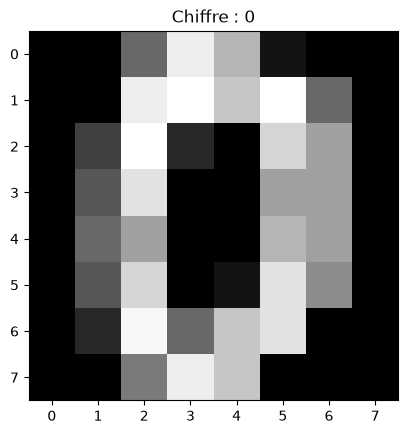

In [4]:

# Afficher la première image
plt.imshow(digit['images'][0], cmap='Greys_r')
plt.title("Chiffre : " + str(digit['target'][0]))
plt.show()


In [5]:

# Variables d'entrée : les images
train_x = digit.data

# Variables de sortie : les chiffres réels
train_y = digit.target

# Division : 75% apprentissage, 25% test
x_train, x_test, y_train, y_test = train_test_split(
    train_x,
    train_y,
    test_size=0.25,
    random_state=42
)

print("Training Set :", x_train.shape)
print("Testing Set :", x_test.shape)


Training Set : (1347, 64)
Testing Set : (450, 64)


In [6]:

# Création du modèle KNN avec 7 voisins
KNN = KNeighborsClassifier(n_neighbors=7)

# Entraînement du modèle
KNN.fit(x_train, y_train)

print("Modèle KNN entraîné avec succès !")


Modèle KNN entraîné avec succès !


In [7]:

# Évaluer le modèle sur les données de test
accuracy = KNN.score(x_test, y_test)

print("Accuracy :", accuracy)
print("Accuracy en % :", accuracy * 100)


Accuracy : 0.9933333333333333
Accuracy en % : 99.33333333333333


In [8]:

# Liste des valeurs de K
k_values = range(1, 21)

# Liste des scores obtenus
scores = []

# Tester chaque valeur de K
for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train, y_train)

    score = model.score(x_test, y_test)
    scores.append(score)

    print(f"K = {k} : Accuracy = {score:.4f}")


K = 1 : Accuracy = 0.9822
K = 2 : Accuracy = 0.9844
K = 3 : Accuracy = 0.9867
K = 4 : Accuracy = 0.9867
K = 5 : Accuracy = 0.9933
K = 6 : Accuracy = 0.9956
K = 7 : Accuracy = 0.9933
K = 8 : Accuracy = 0.9889
K = 9 : Accuracy = 0.9867
K = 10 : Accuracy = 0.9867
K = 11 : Accuracy = 0.9800
K = 12 : Accuracy = 0.9800
K = 13 : Accuracy = 0.9800
K = 14 : Accuracy = 0.9822
K = 15 : Accuracy = 0.9800
K = 16 : Accuracy = 0.9778
K = 17 : Accuracy = 0.9800
K = 18 : Accuracy = 0.9778
K = 19 : Accuracy = 0.9778
K = 20 : Accuracy = 0.9778


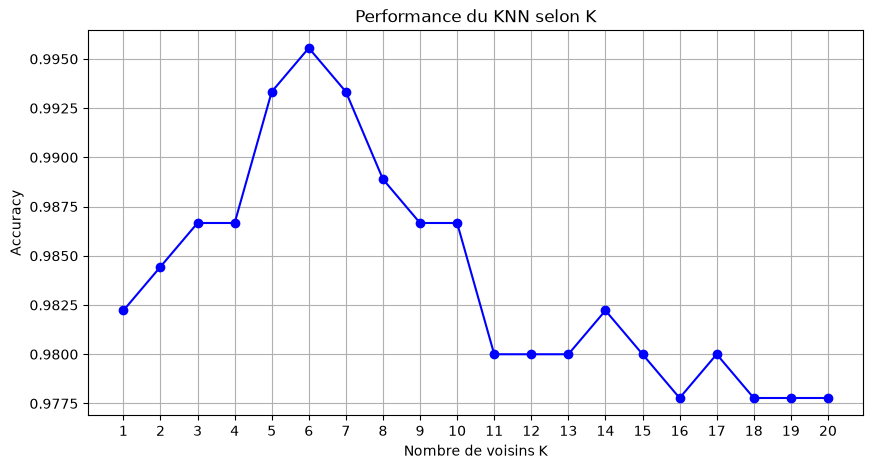

In [9]:

plt.figure(figsize=(10, 5))

plt.plot(k_values, scores, marker='o', color='blue')

plt.xlabel("Nombre de voisins K")
plt.ylabel("Accuracy")
plt.title("Performance du KNN selon K")
plt.xticks(list(k_values))
plt.grid(True)

plt.show()


In [10]:

best_k = list(k_values)[scores.index(max(scores))]

print("Meilleur K observé :", best_k)
print("Accuracy maximale :", max(scores))
print("Accuracy pour K=7 :", scores[6])


Meilleur K observé : 6
Accuracy maximale : 0.9955555555555555
Accuracy pour K=7 : 0.9933333333333333


In [11]:

from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)

    scores_k = cross_val_score(
        model,
        x_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    cv_scores.append(scores_k.mean())

best_k_cv = np.argmax(cv_scores) + 1

print("Meilleur K par validation croisée :", best_k_cv)
print("Accuracy moyenne CV :", max(cv_scores))


Meilleur K par validation croisée : 1
Accuracy moyenne CV : 0.9881261186837393


In [12]:

# Entraîner avec le meilleur K
final_model = KNeighborsClassifier(
    n_neighbors=best_k_cv
)

final_model.fit(x_train, y_train)

# Évaluation finale
final_accuracy = final_model.score(x_test, y_test)

print("Meilleur K :", best_k_cv)
print("Accuracy finale :", final_accuracy)
print("Accuracy finale (%) :", final_accuracy * 100)


Meilleur K : 1
Accuracy finale : 0.9822222222222222
Accuracy finale (%) : 98.22222222222223


In [13]:

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns


In [14]:

# Vérifier les fichiers présents
print(os.listdir("."))

# Charger la base de données
df = pd.read_csv(
    "spam.csv",
    encoding="latin-1"
)[["v1", "v2"]]

# Renommer les colonnes
df.columns = ["label", "message"]

# Afficher les 5 premiers messages
print(df.head())


# Afficher les dimensions
print("Dimensions :", df.shape)


['.ipynb_checkpoints', 'spam.csv', 'TP3_Apprentissage_Supervise.ipynb']
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dimensions : (5572, 2)


label
ham     4825
spam     747
Name: count, dtype: int64


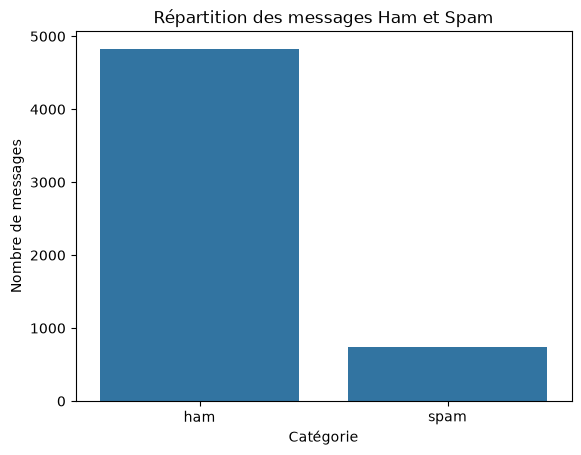

In [15]:

# Nombre de messages par catégorie
print(df["label"].value_counts())

# Visualisation
sns.countplot(data=df, x="label")
plt.title("Répartition des messages Ham et Spam")
plt.xlabel("Catégorie")
plt.ylabel("Nombre de messages")
plt.show()


In [16]:

%pip install nltk


Note: you may need to restart the kernel to use updated packages.


In [1]:

import nltk

# Télécharger les mots vides anglais
nltk.download('stopwords')


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\USER\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [2]:

import string
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

# Charger les stopwords une seule fois
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def process(text):
    # Convertir en minuscules
    text = text.lower()

    # Supprimer les ponctuations
    text = text.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Supprimer les stopwords
    words = [
        word for word in text.split()
        if word not in stop_words
    ]

    # Appliquer le stemming
    return [stemmer.stem(word) for word in words]


In [3]:

print(process(
    "It's holiday and we are playing cricket. "
    "Jeff is playing very well!!!"
))


['holiday', 'play', 'cricket', 'jeff', 'play', 'well']


In [4]:

import pandas as pd

# Charger la base de données SPAM
df = pd.read_csv("spam.csv", encoding="latin-1")[["v1", "v2"]]

# Renommer les colonnes
df.columns = ["label", "message"]

# Vérifier le chargement
print(df.head())
print("Nombre de messages :", len(df))


  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Nombre de messages : 5572


In [5]:

# Afficher les 20 premiers messages nettoyés
print(df['message'][:20].apply(process))


0     [go, jurong, point, crazi, avail, bugi, n, gre...
1                          [ok, lar, joke, wif, u, oni]
2     [free, entri, 2, wkli, comp, win, fa, cup, fin...
3         [u, dun, say, earli, hor, u, c, alreadi, say]
4     [nah, dont, think, goe, usf, live, around, tho...
5     [freemsg, hey, darl, 3, week, word, back, id, ...
6     [even, brother, like, speak, treat, like, aid,...
7     [per, request, mell, mell, oru, minnaminungint...
8     [winner, valu, network, custom, select, receiv...
9     [mobil, 11, month, u, r, entitl, updat, latest...
10    [im, gonna, home, soon, dont, want, talk, stuf...
11    [six, chanc, win, cash, 100, 20000, pound, txt...
12    [urgent, 1, week, free, membership, å£100000, ...
13    [ive, search, right, word, thank, breather, pr...
14                                       [date, sunday]
15    [xxxmobilemovieclub, use, credit, click, wap, ...
16                                     [oh, kim, watch]
17    [eh, u, rememb, 2, spell, name, ye, v, nau

In [6]:

from sklearn.feature_extraction.text import TfidfVectorizer
import time

debut = time.time()

tfidfv = TfidfVectorizer(analyzer=process)

data = tfidfv.fit_transform(df['message'])

print("Dimensions de la matrice :", data.shape)
print("Temps d'exécution :", round(time.time() - debut, 2), "secondes")


Dimensions de la matrice : (5572, 8097)
Temps d'exécution : 2.72 secondes


In [7]:

mess = df.iloc[2]['message']

print("Message original :")
print(mess)

print("\nReprésentation TF-IDF :")
print(tfidfv.transform([mess]))


Message original :
Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's

Représentation TF-IDF :
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21 stored elements and shape (1, 8097)>
  Coords	Values
  (0, 72)	0.2330497030932461
  (0, 413)	0.09987750376879972
  (0, 420)	0.22518719340674634
  (0, 433)	0.22518719340674634
  (0, 833)	0.2190885570936267
  (0, 1180)	0.16669800498830506
  (0, 2076)	0.19516151371199045
  (0, 2246)	0.20302402339849024
  (0, 2748)	0.3571909758763146
  (0, 2868)	0.4660994061864922
  (0, 2969)	0.16669800498830506
  (0, 3091)	0.11505037200973967
  (0, 4592)	0.15903719770411495
  (0, 5768)	0.2330497030932461
  (0, 5815)	0.2330497030932461
  (0, 5856)	0.16027970945850903
  (0, 6959)	0.11759458460817876
  (0, 7099)	0.2190885570936267
  (0, 7276)	0.12336193745345178
  (0, 7708)	0.14471405235314777
  (0, 7741)	0.18906287739887084


In [8]:

j = tfidfv.transform([mess]).toarray()[0]

print('index\tidf\ttfidf\tterm')

for i in range(len(j)):
    if j[i] != 0:
        print(
            i,
            format(tfidfv.idf_[i], '.4f'),
            format(j[i], '.4f'),
            tfidfv.get_feature_names_out()[i],
            sep='\t'
        )


index	idf	tfidf	term
72	8.5271	0.2330	08452810075over18
413	3.6544	0.0999	2
420	8.2394	0.2252	2005
433	8.2394	0.2252	21st
833	8.0163	0.2191	87121
1180	6.0993	0.1667	appli
2076	7.1408	0.1952	comp
2246	7.4285	0.2030	cup
2748	6.5346	0.3572	entri
2868	8.5271	0.4661	fa
2969	6.0993	0.1667	final
3091	4.2096	0.1151	free
4592	5.8190	0.1590	may
5768	8.5271	0.2330	questionstd
5815	8.5271	0.2330	ratetc
5856	5.8645	0.1603	receiv
6959	4.3027	0.1176	text
7099	8.0163	0.2191	tkt
7276	4.5137	0.1234	txt
7708	5.2950	0.1447	win
7741	6.9176	0.1891	wkli


In [9]:

print(process("Hello! We are playing football today."))

print("Nombre de messages :", len(df))


['hello', 'play', 'footbal', 'today']
Nombre de messages : 5572


In [11]:

from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split


In [12]:

# Création du modèle SPAM Filter
spam_filter = Pipeline([
    ('vectorizer', TfidfVectorizer(analyzer=process)),
    ('classifier', MultinomialNB())
])

print("Modèle Spam Filter créé !")


Modèle Spam Filter créé !


In [13]:

x_train, x_test, y_train, y_test = train_test_split(
    df['message'],
    df['label'],
    test_size=0.20,
    random_state=21
)

print("Messages d'apprentissage :", len(x_train))
print("Messages de test :", len(x_test))


Messages d'apprentissage : 4457
Messages de test : 1115


In [14]:

# Entraînement du modèle
spam_filter.fit(x_train, y_train)

print("Modèle Naïve Bayes entraîné avec succès !")


Modèle Naïve Bayes entraîné avec succès !


In [15]:

# Prédictions sur le jeu de test
predictions = spam_filter.predict(x_test)

# Compter les prédictions incorrectes
count = 0

for i in range(len(y_test)):
    if y_test.iloc[i] != predictions[i]:
        count += 1

print("Total number of test cases :", len(y_test))
print("Number of wrong predictions :", count)


Total number of test cases : 1115
Number of wrong predictions : 39


In [16]:

# Créer un tableau des résultats
resultats = pd.DataFrame({
    'Message': x_test.values,
    'Classe réelle': y_test.values,
    'Classe prédite': predictions
})

# Sélectionner les messages mal classés
erreurs = resultats[
    resultats['Classe réelle'] != resultats['Classe prédite']
]

print("Nombre de prédictions erronées :", len(erreurs))

# Afficher les messages mal classés
display(erreurs)


Nombre de prédictions erronées : 39


,Message,Classe réelle,Classe prédite
14,Send a logo 2 ur lover - 2 names joined by a h...,spam,ham
106,sexy sexy cum and text me im wet and warm and ...,spam,ham
128,"Twinks, bears, scallies, skins and jocks are c...",spam,ham
158,Hey Boys. Want hot XXX pics sent direct 2 ur p...,spam,ham
160,YES! The only place in town to meet exciting a...,spam,ham
189,"SMS. ac JSco: Energy is high, but u may not kn...",spam,ham
193,LIFE has never been this much fun and great un...,spam,ham
219,Sorry I missed your call let's talk when you h...,spam,ham
238,I don't know u and u don't know me. Send CHAT ...,spam,ham
245,Oh my god! I've found your number again! I'm s...,spam,ham


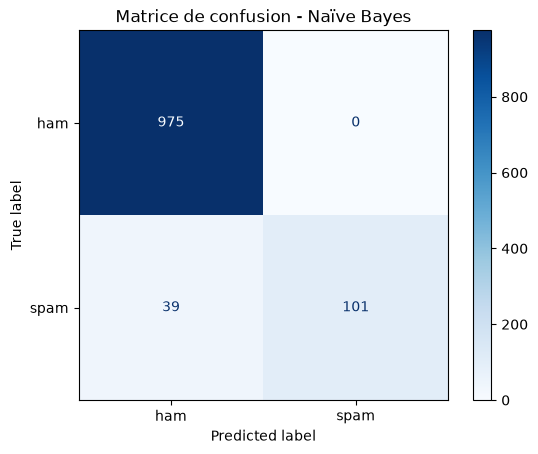

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    predictions,
    labels=['ham', 'spam']
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['ham', 'spam']
)

disp.plot(cmap='Blues')
plt.title("Matrice de confusion - Naïve Bayes")
plt.show()


In [19]:

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    predictions,
    digits=4
))


              precision    recall  f1-score   support

         ham     0.9615    1.0000    0.9804       975
        spam     1.0000    0.7214    0.8382       140

    accuracy                         0.9650      1115
   macro avg     0.9808    0.8607    0.9093      1115
weighted avg     0.9664    0.9650    0.9625      1115



In [20]:

message = """Your cash-balance is currently 500 pounds -
to maximize your cash-in now, send COLLECT to 83600."""

prediction = spam_filter.predict([message])

print("Classe prédite :", prediction[0])


Classe prédite : spam


In [21]:

import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Charger la base de données
df_reg = pd.read_csv("univariateLinearRegression.csv")

# Afficher les premières lignes
print(df_reg.head())

# Afficher le nombre d'observations
print("Nombre d'observations :", len(df_reg))

# Afficher les dimensions
print("Dimensions :", df_reg.shape)


   6.1101   17.592
0  5.5277   9.1302
1  8.5186  13.6620
2  7.0032  11.8540
3  5.8598   6.8233
4  8.3829  11.8860
Nombre d'observations : 96
Dimensions : (96, 2)


In [22]:

# X : population de la ville
X = df_reg.iloc[:, 0]

# Y : bénéfice réalisé
Y = df_reg.iloc[:, 1]

print("Population :")
print(X.head())

print("\nBénéfices :")
print(Y.head())


Population :
0    5.5277
1    8.5186
2    7.0032
3    5.8598
4    8.3829
Name: 6.1101, dtype: float64

Bénéfices :
0     9.1302
1    13.6620
2    11.8540
3     6.8233
4    11.8860
Name: 17.592, dtype: float64


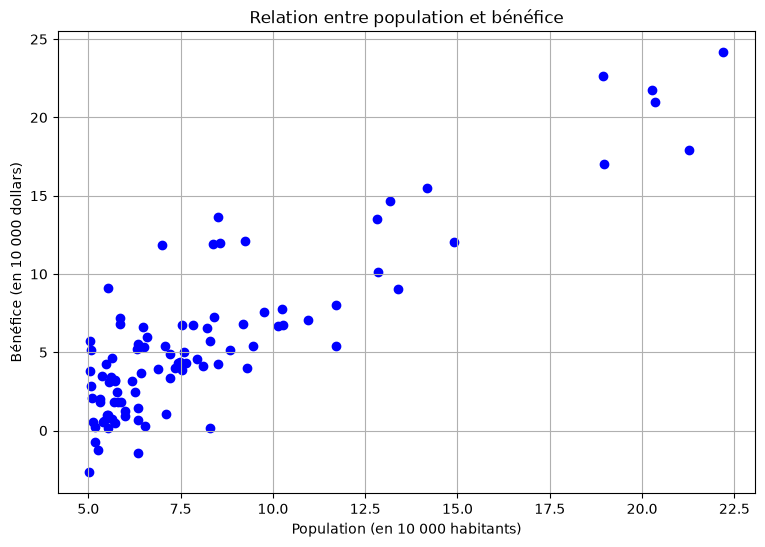

In [23]:

plt.figure(figsize=(9, 6))

plt.scatter(X, Y, color='blue')

plt.xlabel("Population (en 10 000 habitants)")
plt.ylabel("Bénéfice (en 10 000 dollars)")
plt.title("Relation entre population et bénéfice")
plt.grid(True)

plt.show()


In [24]:

# Calcul de la régression linéaire
slope, intercept, r_value, p_value, std_err = stats.linregress(X, Y)

print("Pente (a) :", slope)
print("Ordonnée à l'origine (b) :", intercept)
print("Coefficient de corrélation (r) :", r_value)
print("Coefficient de détermination (R²) :", r_value**2)

# Fonction de prédiction
def F(x):
    return slope * x + intercept

print(f"\nÉquation : Y = {slope:.4f}X + ({intercept:.4f})")


Pente (a) : 1.2135472539083583
Ordonnée à l'origine (b) : -4.211504005424089
Coefficient de corrélation (r) : 0.8721572919685902
Coefficient de détermination (R²) : 0.7606583419339846

Équation : Y = 1.2135X + (-4.2115)


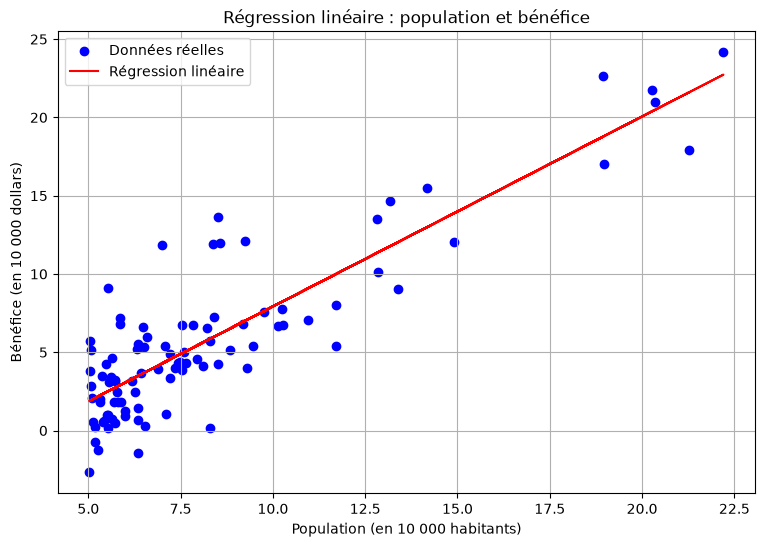

In [25]:

# Calculer les bénéfices prédits
fitLine = F(X)

# Afficher les données réelles
plt.figure(figsize=(9, 6))
plt.scatter(X, Y, color='blue', label='Données réelles')

# Afficher la droite de régression
plt.plot(X, fitLine, color='red', label='Régression linéaire')

plt.xlabel("Population (en 10 000 habitants)")
plt.ylabel("Bénéfice (en 10 000 dollars)")
plt.title("Régression linéaire : population et bénéfice")
plt.legend()
plt.grid(True)
plt.show()


In [26]:

population = 20.27

benefice = F(population)

print("Population :", population * 10000, "habitants")
print("Bénéfice prédit :", benefice)
print("Bénéfice prédit en dollars :", benefice * 10000)


Population : 202700.0 habitants
Bénéfice prédit : 20.38709883129833
Bénéfice prédit en dollars : 203870.9883129833


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler

# Charger la base de données
df_maison = pd.read_excel("multivariateLinearRegression.xlsx")

# Afficher les premières observations
print(df_maison.head())

# Afficher les dimensions
print("Dimensions :", df_maison.shape)

# Afficher les informations sur les colonnes
print(df_maison.info())


   taille_en_pieds_carre  nb_chambres    prix
0                   2104            3  399900
1                   1600            3  329900
2                   2400            3  369000
3                   1416            2  232000
4                   3000            4  539900
Dimensions : (47, 3)
<class 'pandas.DataFrame'>
RangeIndex: 47 entries, 0 to 46
Data columns (total 3 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   taille_en_pieds_carre  47 non-null     int64
 1   nb_chambres            47 non-null     int64
 2   prix                   47 non-null     int64
dtypes: int64(3)
memory usage: 1.2 KB
None


In [28]:

# Variable cible : prix de vente
Y_maison = df_maison["prix"]

# Variables explicatives
X_maison = df_maison[
    ["taille_en_pieds_carre", "nb_chambres"]
]

print("Variables explicatives :")
print(X_maison.head())

print("\nVariable cible :")
print(Y_maison.head())


Variables explicatives :
   taille_en_pieds_carre  nb_chambres
0                   2104            3
1                   1600            3
2                   2400            3
3                   1416            2
4                   3000            4

Variable cible :
0    399900
1    329900
2    369000
3    232000
4    539900
Name: prix, dtype: int64


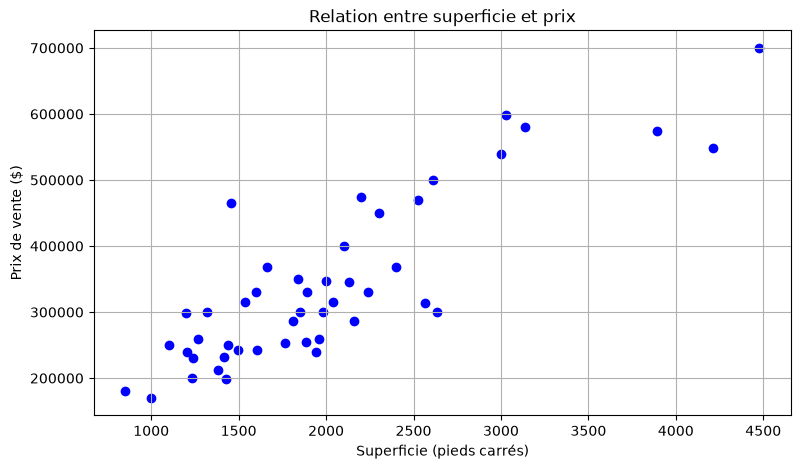

In [29]:

plt.figure(figsize=(9, 5))

plt.scatter(
    df_maison["taille_en_pieds_carre"],
    df_maison["prix"],
    color="blue"
)

plt.xlabel("Superficie (pieds carrés)")
plt.ylabel("Prix de vente ($)")
plt.title("Relation entre superficie et prix")
plt.grid(True)

plt.show()


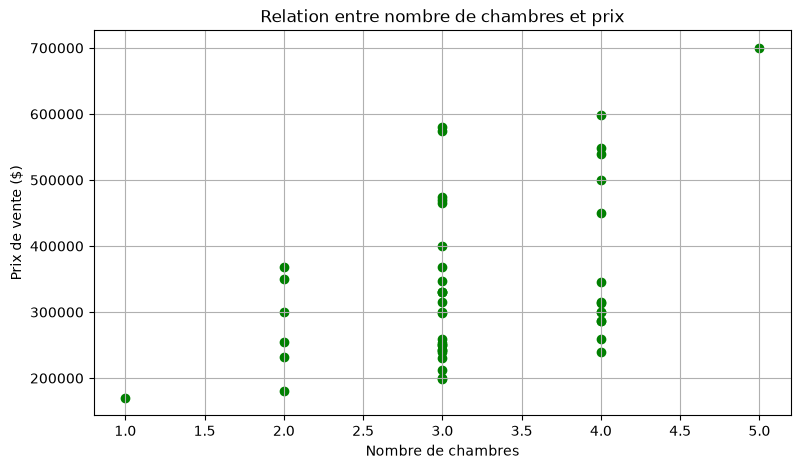

In [30]:

plt.figure(figsize=(9, 5))

plt.scatter(
    df_maison["nb_chambres"],
    df_maison["prix"],
    color="green"
)

plt.xlabel("Nombre de chambres")
plt.ylabel("Prix de vente ($)")
plt.title("Relation entre nombre de chambres et prix")
plt.grid(True)

plt.show()


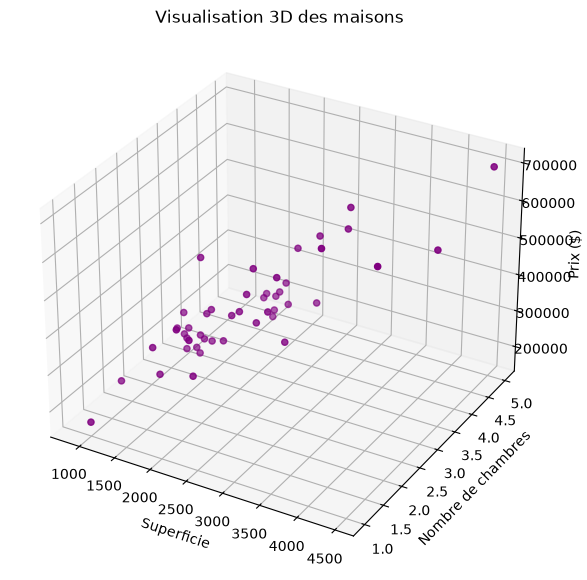

In [31]:

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(
    df_maison["taille_en_pieds_carre"],
    df_maison["nb_chambres"],
    df_maison["prix"],
    color="purple"
)

ax.set_xlabel("Superficie")
ax.set_ylabel("Nombre de chambres")
ax.set_zlabel("Prix ($)")
ax.set_title("Visualisation 3D des maisons")

plt.show()


In [32]:

from sklearn.preprocessing import StandardScaler

# Création du standardiseur
scale = StandardScaler()

# Standardisation des variables explicatives
X_scaled = scale.fit_transform(X_maison)

# Afficher les données standardisées
print("Données standardisées :")
print(X_scaled[:10])


Données standardisées :
[[ 0.13141542 -0.22609337]
 [-0.5096407  -0.22609337]
 [ 0.5079087  -0.22609337]
 [-0.74367706 -1.5543919 ]
 [ 1.27107075  1.10220517]
 [-0.01994505  1.10220517]
 [-0.59358852 -0.22609337]
 [-0.72968575 -0.22609337]
 [-0.78946678 -0.22609337]
 [-0.64446599 -0.22609337]]


In [33]:

import statsmodels.api as sm

# Ajouter une constante pour l'ordonnée à l'origine
X_ols = sm.add_constant(X_scaled)

# Construire le modèle OLS
model = sm.OLS(Y_maison, X_ols).fit()

# Afficher les résultats
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                   prix   R-squared:                       0.733
Model:                            OLS   Adj. R-squared:                  0.721
Method:                 Least Squares   F-statistic:                     60.38
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           2.43e-13
Time:                        22:06:32   Log-Likelihood:                -586.77
No. Observations:                  47   AIC:                             1180.
Df Residuals:                      44   BIC:                             1185.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       3.404e+05   9637.239     35.323      0.0

In [34]:

# Caractéristiques de la nouvelle maison
nouvelle_maison = pd.DataFrame({
    "taille_en_pieds_carre": [4500],
    "nb_chambres": [5]
})

# Standardiser avec le scaler déjà entraîné
nouvelle_maison_scaled = scale.transform(nouvelle_maison)

# Ajouter la constante
nouvelle_maison_ols = sm.add_constant(
    nouvelle_maison_scaled,
    has_constant="add"
)

# Prédire le prix
prix_predit = model.predict(nouvelle_maison_ols)

print("Superficie : 4500 pieds carrés")
print("Nombre de chambres : 5")
print(f"Prix prédit : {prix_predit[0]:,.2f} $")


Superficie : 4500 pieds carrés
Nombre de chambres : 5
Prix prédit : 672,355.85 $


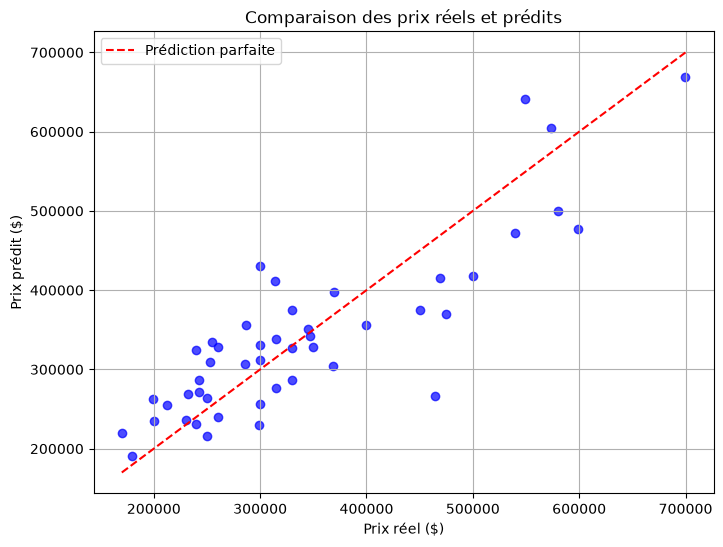

In [35]:

# Prédictions sur les 47 maisons
prix_predictions = model.predict(X_ols)

plt.figure(figsize=(8, 6))

plt.scatter(
    Y_maison,
    prix_predictions,
    color="blue",
    alpha=0.7
)

# Droite idéale : prédiction = valeur réelle
minimum = min(Y_maison.min(), prix_predictions.min())
maximum = max(Y_maison.max(), prix_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--',
    label="Prédiction parfaite"
)

plt.xlabel("Prix réel ($)")
plt.ylabel("Prix prédit ($)")
plt.title("Comparaison des prix réels et prédits")
plt.legend()
plt.grid(True)
plt.show()
